MAE : 3414.399904240967
MSE : 18498081.23312045
RMSE : 4300.939575618385
R2 Score : 0.9839981996253283
   Actual      Predicted
0   98000  104029.730577
1   30000   29200.930768


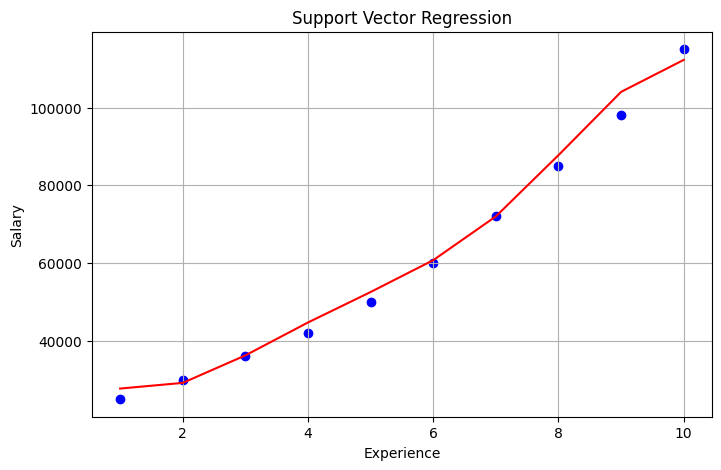

Enter Experience :  19


Predicted Salary : 65270.88546233076


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.DataFrame({
    "Experience":[1,2,3,4,5,6,7,8,9,10],
    "Salary":[25000,30000,36000,42000,50000,60000,72000,85000,98000,115000]
})

X = df[["Experience"]]
y = df["Salary"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

X_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train = X_scaler.fit_transform(X_train)
X_test = X_scaler.transform(X_test)

y_train = y_scaler.fit_transform(
    y_train.values.reshape(-1,1)
).ravel()

model = SVR(
    kernel="rbf",
    C=100,
    epsilon=0.1,
    gamma="scale"
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

y_pred = y_scaler.inverse_transform(
    y_pred.reshape(-1,1)
).ravel()

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE :", rmse)
print("R2 Score :", r2)

result = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print(result)

X_plot = X_scaler.transform(X)

y_plot = model.predict(X_plot)

y_plot = y_scaler.inverse_transform(
    y_plot.reshape(-1,1)
).ravel()

plt.figure(figsize=(8,5))
plt.scatter(X, y, color="blue")
plt.plot(X, y_plot, color="red")
plt.xlabel("Experience")
plt.ylabel("Salary")
plt.title("Support Vector Regression")
plt.grid(True)
plt.show()

exp = float(input("Enter Experience : "))

new_data = [[exp]]

new_data = X_scaler.transform(new_data)

prediction = model.predict(new_data)

prediction = y_scaler.inverse_transform(
    prediction.reshape(-1,1)
)

print("Predicted Salary :", prediction[0][0])